In [2]:
import qgtoolbox as qg
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import xwavelet.wavelet as xwl
import xrft

from tqdm import tqdm
from matplotlib.colors import LogNorm, Normalize
from scipy.ndimage import gaussian_filter
from scipy.signal import find_peaks
from IPython.display import clear_output

dm = qg.DataManager(root_dir='..')
print(dm.root)

/home/slava/Work/climate/wavelet-jet-analysis


In [3]:
EXP = 'huge-jet-atm'
N_EPOCH = 100
METHOD = 'test'

sim_path = dm.make_dir(path=dm.raw, name=EXP)
res_path = dm.make_dir(path=dm.processed, name=EXP)
stat_path = dm.make_dir(path=res_path, name=METHOD)

cfg_path = dm.config / f"{EXP}.yaml"
ds_sim_path = sim_path / f"{EXP}.nc"
ds_stat_path = stat_path / f"{EXP}.nc"

ds_sim_path_e = qg.epoch_path(ds_sim_path, N_EPOCH)
ds_stat_path_e = qg.epoch_path(ds_stat_path, N_EPOCH)

In [4]:
def calc_spectra(ds, gamma=None, n_scale=None):
    x, y = ds.x, ds.y  
    n_grid = ds.attrs['grid.n_grid']
    x0 = ds.x.values[1] - ds.x.values[0]
    if n_scale is None:
        n_scale = n_grid
    s_vals = np.geomspace(2.0, n_grid, n_scale)
    s = xr.DataArray(s_vals, dims=["s"], coords={"s": s_vals})
    Wax = xwl.cwt2(ds.ux, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Way = xwl.cwt2(ds.uy, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Ea = np.abs(Wax)**2 / Wax["s"] * x0**2 + np.abs(Way)**2 / Way["s"] * x0**2
    return Ea

def calc_E_spectra(ds, gamma=None, n_scale=None):
    x, y = ds.x, ds.y  
    n_grid = ds.attrs['grid.n_grid']
    x0 = ds.x.values[1] - ds.x.values[0]
    if n_scale is None:
        n_scale = n_grid
    s_vals = np.geomspace(2.0, n_grid, n_scale)
    s = xr.DataArray(s_vals, dims=["s"], coords={"s": s_vals})
    Waq = xwl.cwt2(ds.q, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Wap = xwl.cwt2(ds.p, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Ea = np.real(Waq * (- np.conj(Wap))) / Waq["s"] * x0**2
    return Ea

def grad(v):
    vh = xrft.fft(v, dim=['y', 'x'])
    lag_y = vh.freq_y.attrs.get('direct_lag', 0.0)
    lag_x = vh.freq_x.attrs.get('direct_lag', 0.0)
    k_x, k_y = 2 * np.pi * vh.freq_x, 2 * np.pi * vh.freq_y
    grad_vxh = 1j * vh * k_x
    grad_vyh = 1j * vh * k_y 
    grad_vx = xrft.ifft(grad_vxh, dim=['freq_y', 'freq_x'], lag=[lag_y, lag_x]).real
    grad_vy = xrft.ifft(grad_vyh, dim=['freq_y', 'freq_x'], lag=[lag_y, lag_x]).real
    return grad_vx, grad_vy

def transfer(ux, uy):
    gradx_ux, grady_ux = grad(ux)
    gradx_uy, grady_uy = grad(uy)
    t_ux = ux * gradx_ux.values +  uy * grady_ux.values
    t_uy = ux * gradx_uy.values +  uy * grady_uy.values
    return t_ux, t_uy

def calc_flux(ds, gamma=None, n_scale=None):
    x, y = ds.x, ds.y  
    n_grid = ds.attrs['grid.n_grid']
    x0 = ds.x.values[1] - ds.x.values[0]
    if n_scale is None:
        n_scale = n_grid
    s_vals = np.geomspace(2.0, n_grid, n_scale)
    s = xr.DataArray(s_vals, dims=["s"], coords={"s": s_vals})
    tx, ty = transfer(ds.ux, ds.uy)

    Waux = xwl.cwt2(ds.ux, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Wauy = xwl.cwt2(ds.uy, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    
    Watx = xwl.cwt2(tx, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Waty = xwl.cwt2(ty, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)

    ea = - np.real(np.conj(Waux) * Watx + np.conj(Wauy) * Waty ) / Waux["s"] * x0**2
    return ea

def plot_wspec(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.Eam.values))
    Eaz = ds.Eaz.isel(time=t_idx)
    Eam = ds.Eam.isel(time=t_idx)
    loglog = axis.loglog(k, Eaz/EEa, color=qg.RED, label='zonal (kx)')
    loglog = axis.loglog(k, Eam/EEa, color=qg.BLUE, label='meridional (ky)')
    axis.set_title(f'Energy Wavelet Spectrum $\\tilde E$ | $\\tilde E_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_ylabel('E(k)')
    axis.set_ylim(1e-8, 1e1)
    axis.grid(True)
    axis.legend()
    return loglog

def plot_wspec_jet(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.Eam_aj.values))
    Eaz_j = ds.Eaz_j.isel(time=t_idx)
    Eam_j = ds.Eam_j.isel(time=t_idx)
    Eaz_aj = ds.Eaz_aj.isel(time=t_idx)
    Eam_aj = ds.Eam_aj.isel(time=t_idx)
    loglog = axis.loglog(k, Eam_j/EEa, color=qg.RED, label='jet (M)', linestyle='-')
    loglog = axis.loglog(k, Eaz_j/EEa, color=qg.RED, label='jet (Z)', linestyle='--')
    loglog = axis.loglog(k, Eam_aj/EEa, color=qg.BLUE, label='anti-jet (M)', linestyle='-')
    loglog = axis.loglog(k, Eaz_aj/EEa, color=qg.BLUE, label='anti-jet (Z)', linestyle='--')
    axis.set_title(f'Energy Wavelet Spectrum $\\tilde E$ | $\\tilde E_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_ylabel('E(k)')
    axis.set_ylim(1e-8, 1e1)
    axis.grid(True)
    axis.legend()
    return loglog

def plot_wtransfer_jet(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.eam_aj.values))
    eaz_j = ds.eaz_j.isel(time=t_idx)
    eam_j = ds.eam_j.isel(time=t_idx)
    eaz_aj = ds.eaz_aj.isel(time=t_idx)
    eam_aj = ds.eam_aj.isel(time=t_idx)
    loglog = axis.plot(k, eam_j/EEa, color=qg.RED, label='jet (M)', linestyle='-')
    loglog = axis.plot(k, eaz_j/EEa, color=qg.RED, label='jet (Z)', linestyle='--')
    loglog = axis.plot(k, eam_aj/EEa, color=qg.BLUE, label='anti-jet (M)', linestyle='-')
    loglog = axis.plot(k, eaz_aj/EEa, color=qg.BLUE, label='anti-jet (Z)', linestyle='--')
    axis.set_title(f'Energy Wavelet Transfer $\\tilde \\varepsilon$ | $\\tilde \\varepsilon_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_xscale('log')
    axis.set_ylabel('$\\varepsilon$ (k)')
    axis.set_ylim(-1.1, +1.1)
    axis.grid(True)
    axis.legend()
    return loglog

def plot_wflux_jet(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.eam_j.cumsum(dim='s').values))
    eaz_j = (ds.eaz_j.cumsum(dim='s')).isel(time=t_idx)
    eam_j = (ds.eam_j.cumsum(dim='s')).isel(time=t_idx)
    eaz_aj = (ds.eaz_aj.cumsum(dim='s')).isel(time=t_idx)
    eam_aj = (ds.eam_aj.cumsum(dim='s')).isel(time=t_idx)
    loglog = axis.plot(k, eam_j/EEa, color=qg.RED, label='jet (M)', linestyle='-')
    loglog = axis.plot(k, eaz_j/EEa, color=qg.RED, label='jet (Z)', linestyle='--')
    loglog = axis.plot(k, eam_aj/EEa, color=qg.BLUE, label='anti-jet (M)', linestyle='-')
    loglog = axis.plot(k, eaz_aj/EEa, color=qg.BLUE, label='anti-jet (Z)', linestyle='--')
    axis.set_title(f'Energy Wavelet Flux $\\tilde \\varepsilon$ | $\\tilde \\varepsilon_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_xscale('log')
    axis.set_ylabel('$\\varepsilon$ (k)')
    axis.set_ylim(-1.1, +1.1)
    axis.grid(True)
    axis.legend()
    return loglog


In [4]:
ds = qg.load_simulation(ds_sim_path, n_epoch=10, k_epoch=91)
ds = qg.calc_statistics(ds)
ds = qg.calc_fourier(ds)
# qg.save_dataset(data=ds, path=ds_stat_path)

# ds = qg.load_dataset(ds_sim_path_e)
# ds = qg.calc_statistics(ds)
# ds = qg.calc_fourier(ds)
# qg.save_dataset(data=ds, path=ds_stat_path_e)

In [5]:
ds

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 1000, y: 256, x: 256, kx: 256, ky: 256, k: 45)
Coordinates:
  * time     (time) float64 8kB 9.001e+03 9.002e+03 ... 9.999e+03 1e+04
  * y        (y) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * x        (x) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * kx       (kx) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * ky       (ky) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * k        (k) float64 360B 1.874 4.4 7.16 9.981 ... 117.4 120.2 123.0 125.9
    lev      int64 8B 1
Data variables: (12/14)
    q        (time, y, x) float64 524MB -0.2409 -0.3504 ... -0.6038 -0.5918
    ux       (time, y, x) float64 524MB 0.02535 0.02794 ... 0.0956 0.0992
    uy       (time, y, x) float64 524MB -0.01363 -0.01718 ... 0.02769 0.02382
    p        (time, y, x) float64 524MB -0.008248 -0.008622 ... -0.008434
    v        (time, y, x) float64 524MB 0.02878 0.0328 0.03846 ... 0.09953 0.102
    qp       (time, y, x) float64 524MB -0.1795 -0.289 -0.3044 ... 30.75 30.76
    ...       ...
    eh       (time, ky, kx) float64 524MB 2.603e-35 2.419e-35 ... 3.002e-35
    ehx      (time, y, kx) float64 524MB 1.118e-37 1.896e-35 ... 1.832e-35
    ehy      (time, ky, x) float64 524MB 4.312e-36 6.441e-37 ... 2.326e-37
    Ehr      (time, k) float64 360kB 1.463 4.775 0.4077 ... 8.191e-28 2.394e-32
    Ehx      (time, kx) float64 2MB 3.816e-35 7.906e-35 ... 9.384e-36 9.907e-35
    Ehy      (time, ky) float64 2MB 1.205e-35 1.648e-35 ... 3.072e-35 3.673e-35
Attributes: (12/13)
    title:                   Huge Anisotropic 2D Turbulence
    source:                  pyqg.BTModel
    architecture.n_threads:  1
    grid.n_grid:             256
    model.rek:               0.0001
    model.cnu:               0.2
    ...                      ...
    model.kf:                32.0
    model.dkf:               2.0
    model.beta:              5.0
    simulation.dt:           0.01
    simulation.t_write:      1.0
    simulation.t_epoch:      100.0

In [5]:
x0 = 128
y_j = 2.2
y_aj = 3.2
n_jets = 3
n_grid = ds.attrs['grid.n_grid']
n_times = len(ds.time)
x = ds.x.values
y = ds.y.values
V = np.abs(ds.ux).max().values

ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)

Jet_Idx, AJet_Idx = [], []

vx = ds_m.ux.isel(time=-1, x=x0).values / V
vx_periodic = np.concatenate([vx, vx])
peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
peaks_idx = peaks_idx[peaks_idx < n_grid]
top = peaks_idx[np.argsort(vx[peaks_idx])[::-1][:n_jets]]
if len(top) < n_jets:
    top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
jet_idx = np.sort(top)
j_idx = jet_idx[np.argmin(np.abs(y[jet_idx] - y_j))]

print(y_j, y[j_idx])
y_j = y[j_idx]

vx = ds_m.ux.isel(time=-1, x=x0).values / V
avx = -vx
vx_periodic = np.concatenate([avx, avx])
peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
peaks_idx = peaks_idx[peaks_idx < n_grid]
top = peaks_idx[np.argsort(avx[peaks_idx])[::-1][:n_jets]]
if len(top) < n_jets:
    top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
ajet_idx = np.sort(top)
aj_idx = ajet_idx[np.argmin(np.abs(y[ajet_idx] - y_aj))]
print(y_aj, y[aj_idx])
y_aj = y[aj_idx]

for time in range(len(ds.time)):
    vx = ds.ux.isel(time=time, x=x0).values / V
    vx_periodic = np.concatenate([vx, vx])
    peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
    peaks_idx = peaks_idx[peaks_idx < n_grid]
    top = peaks_idx[np.argsort(vx[peaks_idx])[::-1][:n_jets]]
    if len(top) < n_jets:
        top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
    jet_idx = np.sort(top)
    j_idx = jet_idx[np.argmin(np.abs(y[jet_idx] - y_j))]
    Jet_Idx.append(j_idx)

for time in range(len(ds.time)):
    vx = ds.ux.isel(time=time, x=x0).values / V
    avx = -vx
    vx_periodic = np.concatenate([avx, avx])
    peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
    peaks_idx = peaks_idx[peaks_idx < n_grid]
    top = peaks_idx[np.argsort(avx[peaks_idx])[::-1][:n_jets]]
    if len(top) < n_jets:
        top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
    ajet_idx = np.sort(top)
    aj_idx = ajet_idx[np.argmin(np.abs(y[ajet_idx] - y_aj))]
    AJet_Idx.append(aj_idx)


fig, axis = plt.subplots(ncols=2, nrows=1, figsize=(10,5))
vel_z = qg.plot_zonal_velocity(ds_m, axis[0], t_idx=-1, x0=x0)
vel_y = qg.plot_y_velocity(ds_m, axis[1], t_idx=-1, x0=x0)
# spec = plot_wspec_jet(ds_m, axis[2], t_idx=-1)

axis[0].axhline(y_j, color='red', linestyle='-')
axis[1].axhline(y_j, color='red', linestyle='-')


axis[0].axhline(y_aj, color='blue', linestyle='-')
axis[1].axhline(y_aj, color='blue', linestyle='-')

fig.tight_layout()
# fig.savefig(stat_path / 'avg-spec.png', dpi=1000) 
plt.show()
plt.close()

NameError: name 'ds' is not defined

In [7]:
Eaz_Jet, Eam_Jet = [], []
Eaz_AJet, Eam_AJet = [], []
n_scale = 100
for time in tqdm(range(len(ds.time))):
    jet_idx = Jet_Idx[time]
    ajet_idx = AJet_Idx[time]

    Ea_jet = calc_flux(ds.isel(time=time), gamma=(x[x0], y_j), n_scale=n_scale)
    Eaz_jet = Ea_jet.sel(angle=0.0, method='nearest')
    Eam_jet = Ea_jet.sel(angle=np.pi/2, method='nearest')
    Eaz_Jet.append(Eaz_jet)
    Eam_Jet.append(Eam_jet)

    Ea_ajet = calc_flux(ds.isel(time=time), gamma=(x[x0], y_aj), n_scale=n_scale)
    Eaz_ajet = Ea_ajet.sel(angle=0.0, method='nearest')
    Eam_ajet = Ea_ajet.sel(angle=np.pi/2, method='nearest')
    Eaz_AJet.append(Eaz_ajet)
    Eam_AJet.append(Eam_ajet)

Eaz_jet = xr.concat(Eaz_Jet, dim='time', data_vars='all')
Eam_jet = xr.concat(Eam_Jet, dim='time', data_vars='all')
Eaz_ajet = xr.concat(Eaz_AJet, dim='time', data_vars='all')
Eam_ajet = xr.concat(Eam_AJet, dim='time', data_vars='all')

ds['eaz_j'] = Eaz_jet
ds['eam_j'] = Eam_jet
ds['eaz_aj'] = Eaz_ajet
ds['eam_aj'] = Eam_ajet

100%|██████████| 1000/1000 [1:29:09<00:00,  5.35s/it]


In [7]:
ds_yjet = xr.DataArray(y_j*np.ones(len(ds.time)), dims=["time"], coords={"time":ds.time})
ds_yajet = xr.DataArray(y_aj*np.ones(len(ds.time)), dims=["time"], coords={"time":ds.time})
ds_xjet = xr.DataArray(x[x0]*np.ones(len(ds.time)), dims=["time"], coords={"time":ds.time})
ds_xajet = xr.DataArray(x[x0]*np.ones(len(ds.time)), dims=["time"], coords={"time":ds.time})
ds['x_jet'] = ds_xjet
ds['y_jet'] = ds_yjet
ds['x_ajet'] = ds_xajet
ds['y_ajet'] = ds_yajet

In [8]:
# qg.save_dataset(data=ds, path=ds_stat_path)
# ds
ds = qg.load_dataset(ds_stat_path)
ds

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 1000, y: 256, x: 256, ky: 256, kx: 256, k: 45, s: 100)
Coordinates:
  * time     (time) float64 8kB 9.001e+03 9.002e+03 ... 9.999e+03 1e+04
  * y        (y) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * x        (x) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * ky       (ky) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * kx       (kx) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * k        (k) float64 360B 1.874 4.4 7.16 9.981 ... 117.4 120.2 123.0 125.9
  * s        (s) float64 800B 0.04909 0.05155 0.05414 ... 5.697 5.983 6.283
    lev      int64 8B 1
    angle    float64 8B 0.0
Data variables: (12/22)
    q        (time, y, x) float64 524MB -0.2409 -0.3504 ... -0.6038 -0.5918
    ux       (time, y, x) float64 524MB 0.02535 0.02794 ... 0.0956 0.0992
    uy       (time, y, x) float64 524MB -0.01363 -0.01718 ... 0.02769 0.02382
    p        (time, y, x) float64 524MB -0.008248 -0.008622 ... -0.008434
    v        (time, y, x) float64 524MB 0.02878 0.0328 0.03846 ... 0.09953 0.102
    qp       (time, y, x) float64 524MB -0.1795 -0.289 -0.3044 ... 30.75 30.76
    ...       ...
    eaz_aj   (time, s) float64 800kB 4.232e-15 3.141e-15 ... -6.838e-14
    eam_aj   (time, s) float64 800kB -7.161e-15 -5.39e-15 ... -1.849e-12
    x_jet    (time) float64 8kB 3.154 3.154 3.154 3.154 ... 3.154 3.154 3.154
    y_jet    (time) float64 8kB 2.148 2.148 2.148 2.148 ... 2.148 2.148 2.148
    x_ajet   (time) float64 8kB 3.154 3.154 3.154 3.154 ... 3.154 3.154 3.154
    y_ajet   (time) float64 8kB 3.399 3.399 3.399 3.399 ... 3.399 3.399 3.399
Attributes: (12/13)
    title:                   Huge Anisotropic 2D Turbulence
    source:                  pyqg.BTModel
    architecture.n_threads:  1
    grid.n_grid:             256
    model.rek:               0.0001
    model.cnu:               0.2
    ...                      ...
    model.kf:                32.0
    model.dkf:               2.0
    model.beta:              5.0
    simulation.dt:           0.01
    simulation.t_write:      1.0
    simulation.t_epoch:      100.0

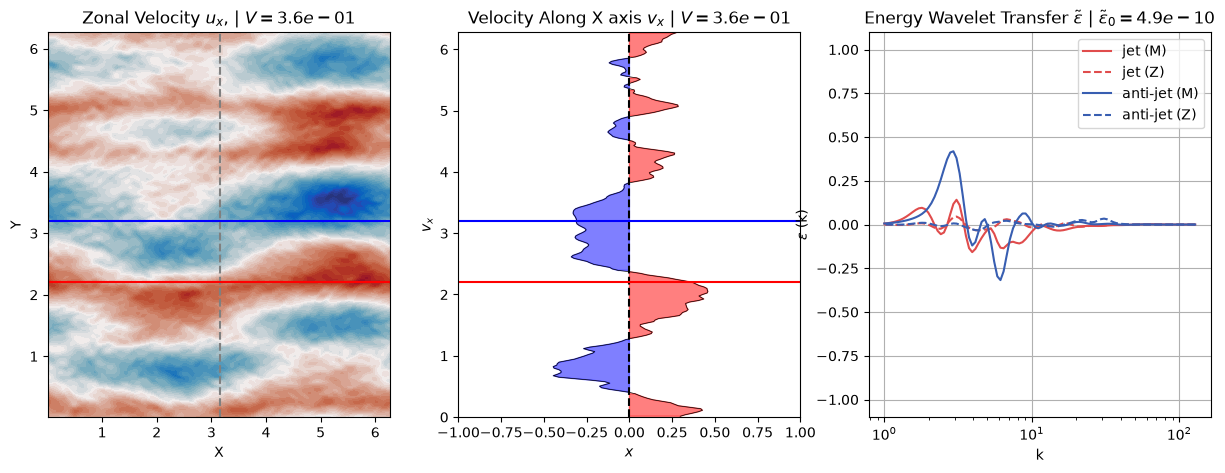

In [9]:
for time in range(10):
    clear_output(wait=True)
    fig, axis = plt.subplots(ncols=3, nrows=1, figsize=(15,5))
    vel_z = qg.plot_zonal_velocity(ds, axis[0], t_idx=time, x0=x0)
    vel_y = qg.plot_y_velocity(ds, axis[1], t_idx=time, x0=x0)
    wspec = plot_wtransfer_jet(ds, axis[2], t_idx=time)

    # jet_idx = Jet_Idx[time]
    axis[0].axhline(y_j, color='red', linestyle='-')
    axis[1].axhline(y_j, color='red', linestyle='-')

    # ajet_idx = AJet_Idx[time]
    axis[0].axhline(y_aj, color='blue', linestyle='-')
    axis[1].axhline(y_aj, color='blue', linestyle='-')

    plt.show()
    plt.close()

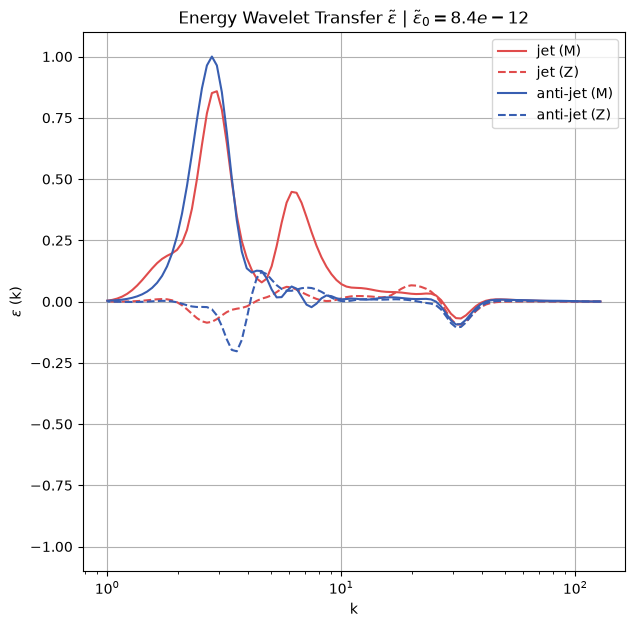

In [11]:
n_grid = ds.attrs['grid.n_grid']
A_f = ds.attrs['model.af']
k_f = ds.attrs['model.kf']
r_ek = ds.attrs['model.rek']
beta = ds.attrs['model.beta']
epsilon = A_f**2/k_f**2

k_nu = 1/3 * n_grid
k_b = (beta**3/epsilon)**(1/5)
k_r = (n_grid * r_ek*beta**2/epsilon)**(1/4)

ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_wtransfer_jet(ds_m, axis, t_idx=-1)
# axis.axvline(k_f, color='yellow', linestyle='--')
# axis.axvline(k_b, color='blue', linestyle='--')
# axis.axvline(k_r, color='red', linestyle='--')
# fig.savefig(stat_path / 'wspec.png', dpi=1000)'

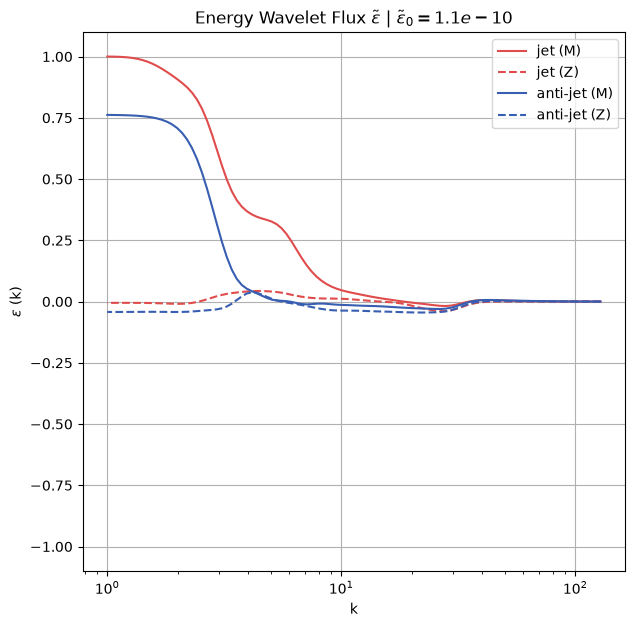

In [12]:
ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_wflux_jet(ds_m, axis, t_idx=-1)
# axis.axvline(k_f, color='yellow', linestyle='--')
# axis.axvline(k_b, color='blue', linestyle='--')
# axis.axvline(k_r, color='red', linestyle='--')
# fig.savefig(stat_path / 'wspec.png', dpi=1000)'


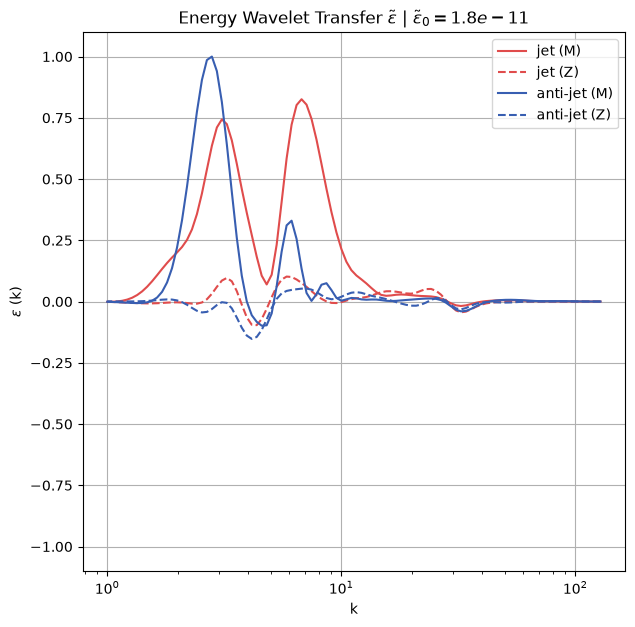

In [367]:
ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_wtransfet_jet(ds_m, axis, t_idx=-1)
# fig.savefig(stat_path / 'wspec.png', dpi=1000)'

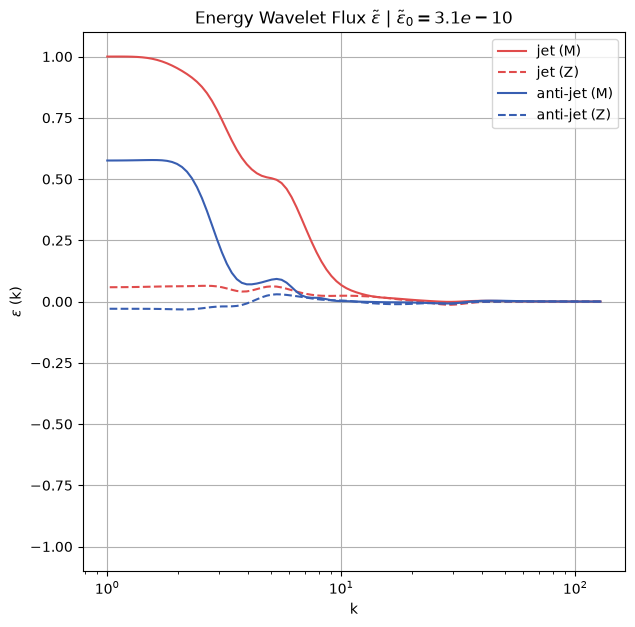

In [368]:
ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_wflux_jet(ds_m, axis, t_idx=-1)
# fig.savefig(stat_path / 'wspec.png', dpi=1000)'

In [351]:
print(ds_m.eam_j)

<xarray.DataArray 'eam_j' (time: 1, s: 100)> Size: 800B
array([[-5.03185888e-16, -2.53922609e-16,  4.60284641e-17,
         5.04717395e-16,  1.36717296e-15,  2.97657448e-15,
         5.66214369e-15,  9.53526296e-15,  1.42747096e-14,
         1.90875136e-14,  2.30340159e-14,  2.57582653e-14,
         2.83146936e-14,  3.32535511e-14,  4.31357609e-14,
         5.81401952e-14,  7.51709139e-14,  8.97564953e-14,
         9.86192230e-14,  1.00275389e-13,  9.43068604e-14,
         8.10368592e-14,  6.07129430e-14,  3.08925464e-14,
        -1.57053331e-14, -8.78247729e-14, -1.83858284e-13,
        -2.78008361e-13, -3.21751124e-13, -2.72165486e-13,
        -1.29350221e-13,  5.60394162e-14,  2.18598330e-13,
         3.22047358e-13,  3.70772137e-13,  3.90441976e-13,
         4.05436674e-13,  4.28888584e-13,  4.62316827e-13,
         4.96692148e-13,  5.13392119e-13,  4.94312181e-13,
         4.46029926e-13,  4.17885002e-13,  4.82843032e-13,
         6.83047136e-13,  9.89178442e-13,  1.32044714e-12,


In [34]:
ds

<xarray.Dataset> Size: 577MB
Dimensions:  (time: 100, y: 256, x: 256, kx: 256, ky: 256, k: 45)
Coordinates:
  * time     (time) float64 800B 9.901e+03 9.902e+03 ... 9.999e+03 1e+04
  * y        (y) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * x        (x) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * kx       (kx) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * ky       (ky) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * k        (k) float64 360B 1.874 4.4 7.16 9.981 ... 117.4 120.2 123.0 125.9
    lev      int64 8B 1
Data variables: (12/14)
    q        (time, y, x) float64 52MB -0.8546 -0.6639 ... -0.6038 -0.5918
    ux       (time, y, x) float64 52MB 0.04114 0.03695 0.03512 ... 0.0956 0.0992
    uy       (time, y, x) float64 52MB -0.0589 -0.05951 ... 0.02769 0.02382
    p        (time, y, x) float64 52MB 0.02546 0.024 ... -0.009064 -0.008434
    v        (time, y, x) float64 52MB 0.07184 0.07005 0.06825 ... 0.09953 0.102
    qp       (time, y, x) float64 52MB -0.7933 -0.6026 -0.4501 ... 30.75 30.76
    ...       ...
    eh       (time, ky, kx) float64 52MB 2.91e-35 1.983e-34 ... 3.002e-35
    ehx      (time, y, kx) float64 52MB 1.61e-37 1.861e-35 ... 1.832e-35
    ehy      (time, ky, x) float64 52MB 6.441e-37 6.745e-36 ... 2.326e-37
    Ehr      (time, k) float64 36kB 1.616 4.79 0.3851 ... 8.191e-28 2.394e-32
    Ehx      (time, kx) float64 205kB 3.337e-35 6.511e-35 ... 9.907e-35
    Ehy      (time, ky) float64 205kB 2.209e-35 2.119e-35 ... 3.673e-35
Attributes: (12/13)
    title:                   Huge Anisotropic 2D Turbulence
    source:                  pyqg.BTModel
    architecture.n_threads:  1
    grid.n_grid:             256
    model.rek:               0.0001
    model.cnu:               0.2
    ...                      ...
    model.kf:                32.0
    model.dkf:               2.0
    model.beta:              5.0
    simulation.dt:           0.01
    simulation.t_write:      1.0
    simulation.t_epoch:      100.0

In [ ]:

# uxh = uxh.assign_coords({
#     'freq_x': 2 * np.pi * uxh.freq_x,
#     'freq_y': 2 * np.pi * uxh.freq_y,
# }).rename({'freq_x': 'kx', 'freq_y': 'ky'})

# uyh = xrft.fft(ds.uy, dim=['y', 'x'])
# uyh = uyh.assign_coords({
#     'freq_x': 2 * np.pi * uyh.freq_x,
#     'freq_y': 2 * np.pi * uyh.freq_y,
# }).rename({'freq_x': 'kx', 'freq_y': 'ky'})



In [49]:
uxh = xrft.fft(ds.ux, dim=['y', 'x'])
ux = xrft.ifft(uxh, dim=['freq_y', 'freq_x'])
uxh

/home/slava/miniconda3/envs/ocean/lib/python3.11/site-packages/xrft/xrft.py:560: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)


<xarray.DataArray (time: 100, freq_y: 256, freq_x: 256)> Size: 105MB
array([[[ 5.35241324e-18-2.25505540e-31j,
          3.72443297e-18+1.35254893e-17j,
          2.51266201e-19+5.86403509e-20j, ...,
         -6.38970662e-19-5.38015930e-19j,
          3.96949228e-19+1.45853013e-18j,
         -1.70783812e-18+1.25344360e-17j],
        [-3.43725052e-18-1.75299764e-19j,
          5.23247953e-18-2.61236602e-18j,
         -1.96073202e-18+8.13905068e-19j, ...,
         -9.59627919e-20-6.36150967e-19j,
          1.91108147e-18-9.37108783e-20j,
          9.82747865e-18-3.15849069e-18j],
        [ 8.15394274e-19+3.28558929e-18j,
         -5.61794187e-18+4.66344156e-18j,
          2.64262309e-19+4.62625780e-19j, ...,
         -1.87996202e-18-2.35272071e-18j,
         -2.14978433e-18+1.75679035e-18j,
          1.27312219e-18-9.34386925e-19j],
        ...,
        [ 1.35433628e-18+3.27916336e-18j,
...
         -4.59540578e-19+1.27144168e-18j],
        ...,
        [-1.84083277e-18-1.98584216e-19j,
          2.84661228e-18+4.03776850e-18j,
         -1.59410766e-20+2.63144383e-18j, ...,
          3.10171165e-19+2.22181275e-18j,
          2.88790326e-18+8.14321727e-19j,
         -6.52032252e-18+3.07796669e-18j],
        [ 3.80853079e-18+1.74049250e-18j,
         -2.86468148e-18-3.30484055e-18j,
         -9.16903318e-19-1.11733318e-18j, ...,
          2.34469362e-18-8.60894114e-19j,
          2.41426551e-18-7.75744855e-19j,
          2.31272333e-18-1.22584595e-19j],
        [-3.54458686e-18-1.45531952e-18j,
         -2.27593018e-18+2.19253504e-18j,
         -2.66881986e-18+2.66388228e-19j, ...,
         -7.76686737e-19-2.17555356e-18j,
          1.02475298e-18+2.12621834e-18j,
          3.07917835e-18+1.40348385e-20j]]])
Coordinates:
  * time     (time) float64 800B 9.901e+03 9.902e+03 ... 9.999e+03 1e+04
  * freq_y   (freq_y) float64 2kB -20.37 -20.21 -20.05 ... 19.89 20.05 20.21
  * freq_x   (freq_x) float64 2kB -20.37 -20.21 -20.05 ... 19.89 20.05 20.21
    lev      int64 8B 1
Attributes:
    spacing:  0.15915494309189526

In [47]:
ux_0 = ds.ux.values
ux_1 = ux.values
delta = np.abs(ux_0 - ux_1)
np.max(delta)

2.442582515515173e-15

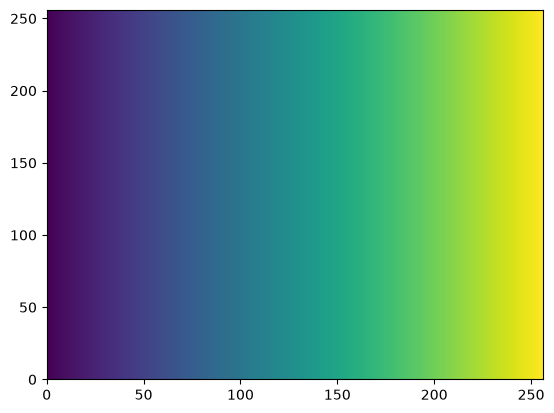

In [112]:
x = ds.x.values
X = np.broadcast_to(x, (len(x), len(x)))
plt.pcolormesh(X[:, :])

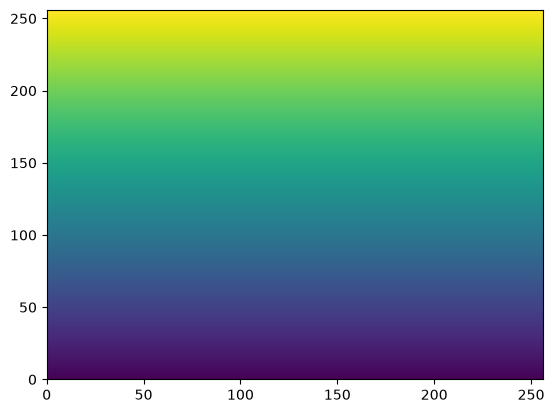

In [113]:
y = ds.y.values
Y = np.broadcast_to(y, (len(y), len(y))).T
plt.pcolormesh(Y[:, :])

In [317]:
def grad(v):
    vh = xrft.fft(v, dim=['y', 'x'])
    lag_y = vh.freq_y.attrs.get('direct_lag', 0.0)
    lag_x = vh.freq_x.attrs.get('direct_lag', 0.0)
    k_x, k_y = 2 * np.pi * vh.freq_x, 2 * np.pi * vh.freq_y
    grad_vxh = 1j * vh * k_x
    grad_vyh = 1j * vh * k_y 
    grad_vx = xrft.ifft(grad_vxh, dim=['freq_y', 'freq_x'], lag=[lag_y, lag_x]).real
    grad_vy = xrft.ifft(grad_vyh, dim=['freq_y', 'freq_x'], lag=[lag_y, lag_x]).real
    return grad_vx, grad_vy

In [318]:
v =  ux * 0.0 + np.sin(X) * np.cos(2*Y)
grad_vx, grad_vy = grad(v)
# print(grad_vy)
# v.isel(time=0).isel(x=0)

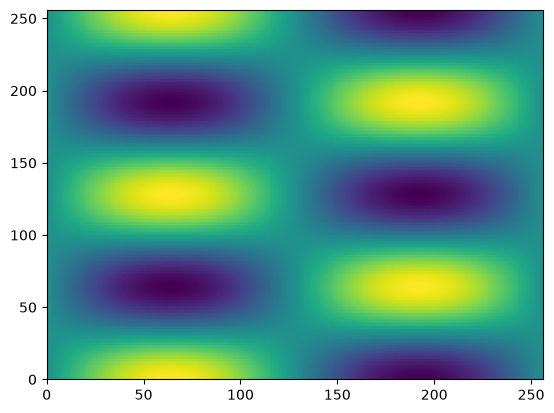

In [319]:
plt.pcolormesh(v.isel(time=0))

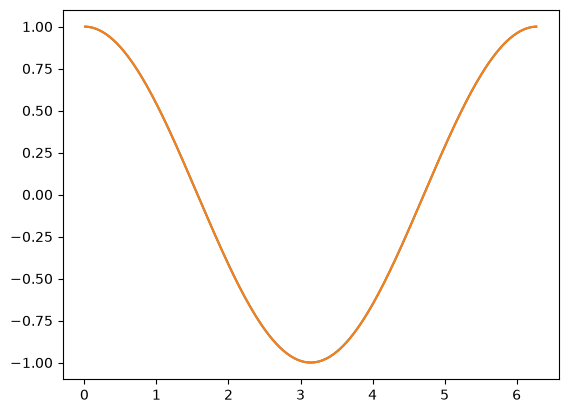

In [320]:
plt.plot(x, grad_vx.isel(time=0).isel(y=0))
plt.plot(x, np.cos(x))

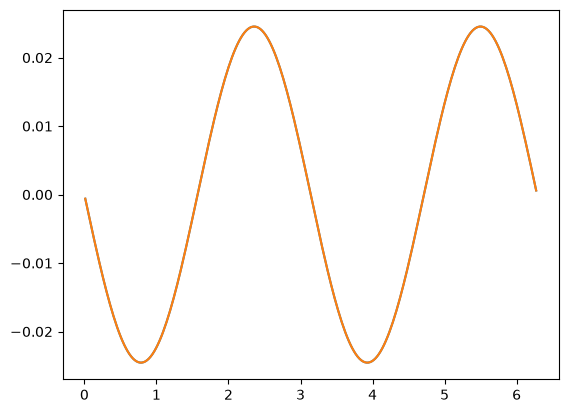

In [321]:
plt.plot(y, grad_vy.isel(time=0).isel(x=0))
plt.plot(y, - 2 * np.sin(2*y) * np.sin(x[0]))

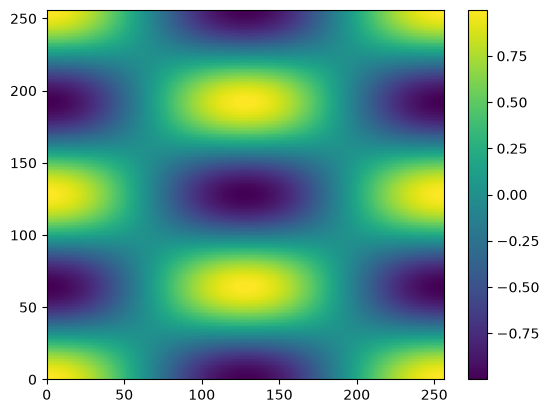

In [322]:
plt.pcolormesh(grad_vx.isel(time=0))
plt.colorbar()
# print(grad_vy.isel(time=0))

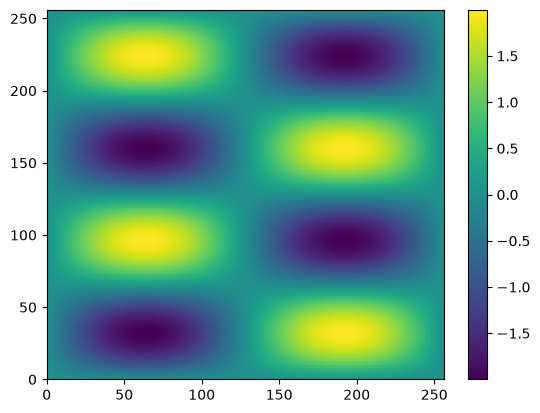

In [323]:
plt.pcolormesh(grad_vy.isel(time=0))
plt.colorbar()

In [ ]:
def grad(v):
    vh = xrft.fft(v, dim=['y', 'x'])
    k_x, k_y = 2 * np.pi * vh.freq_x, 2 * np.pi * vh.freq_y
    grad_vxh = 1j * vh * k_x
    grad_vyh = 1j * vh * k_y 
    grad_vx = np.real(xrft.ifft(grad_vxh, dim=['freq_y', 'freq_x']))
    grad_vy = np.real(xrft.ifft(grad_vyh, dim=['freq_y', 'freq_x']))
    return grad_vx, grad_vy

def transfer(ux, uy):
    gradx_ux, grady_ux = grad(ux)
    gradx_uy, grady_uy = grad(uy)
    t_ux = ux * gradx_ux.values +  uy * grady_ux.values
    t_uy = ux * gradx_uy.values +  uy * grady_uy.values
    return t_ux, t_uy

def calc_flux(ds, gamma=None, n_scale=None):
    x, y = ds.x, ds.y  
    n_grid = ds.attrs['grid.n_grid']
    x0 = ds.x.values[1] - ds.x.values[0]
    if n_scale is None:
        n_scale = n_grid
    s_vals = np.geomspace(2.0, n_grid, n_scale)
    s = xr.DataArray(s_vals, dims=["s"], coords={"s": s_vals})
    tx, ty = transfer(ds.ux, ds.uy)

    Waux = xwl.cwt2(ds.ux, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Wauy = xwl.cwt2(ds.uy, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    
    Watx = xwl.cwt2(tx, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Waty = xwl.cwt2(ty, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)

    ea = - np.real(np.conj(Waux) * Watx + np.conj(Wauy) * Waty ) / Waux["s"] * x0**2
    return ea

In [283]:
ux, uy = ds.ux, ds.uy
t_ux, t_uy = transfer(ux, uy)

/home/slava/miniconda3/envs/ocean/lib/python3.11/site-packages/xrft/xrft.py:560: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)
/home/slava/miniconda3/envs/ocean/lib/python3.11/site-packages/xrft/xrft.py:560: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)
/home/slava/miniconda3/envs/ocean/lib/python3.11/site-packages/xrft/xrft.py:560: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)
/home/slava/miniconda3/envs/ocean/lib/python3.11/site-packages/xrft/xrft.py:560: Futu

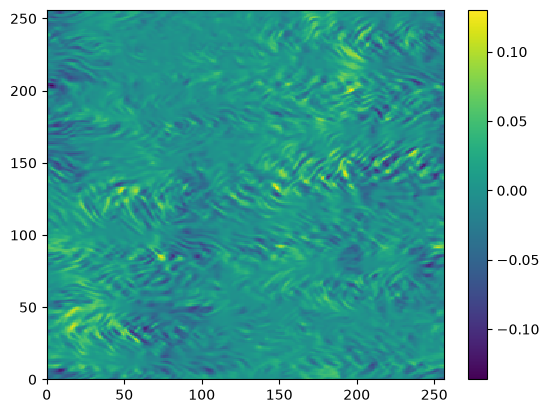

In [285]:
plt.pcolormesh(t_ux.isel(time=0))
plt.colorbar()

In [287]:
ea = calc_flux(ds, gamma=(0,0), n_scale=10)

/home/slava/miniconda3/envs/ocean/lib/python3.11/site-packages/xrft/xrft.py:560: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)
/home/slava/miniconda3/envs/ocean/lib/python3.11/site-packages/xrft/xrft.py:560: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)
/home/slava/miniconda3/envs/ocean/lib/python3.11/site-packages/xrft/xrft.py:560: FutureWarning: Default ifft's behaviour (lag=None) changed! Default value of lag was zero (centered output coordinates) and is now set to transformed coordinate's attribute: 'direct_lag'.
  warnings.warn(msg, FutureWarning)
/home/slava/miniconda3/envs/ocean/lib/python3.11/site-packages/xrft/xrft.py:560: Futu

In [280]:
ea

<xarray.DataArray (time: 100, angle: 2, s: 10)> Size: 16kB
array([[[ 6.14526304e-17,  9.10832667e-16,  2.07917797e-13, ...,
          1.41471805e-11, -4.39070494e-12,  2.27932452e-13],
        [-4.88318820e-15,  2.55524556e-13,  2.97375856e-12, ...,
         -1.82948334e-10, -4.64587248e-12,  8.58735581e-13]],

       [[ 1.37827705e-18,  5.28986092e-16, -2.09667805e-13, ...,
          1.40728403e-11,  2.46312163e-12,  2.41684740e-13],
        [-3.36997205e-15,  8.14986372e-13,  4.62812706e-12, ...,
         -1.40810913e-10, -6.99424340e-12,  8.60196741e-13]],

       [[ 2.42160929e-19, -1.01203629e-16,  2.32361140e-14, ...,
         -7.38313383e-13,  4.68680855e-12,  2.35252133e-13],
        [-1.77407758e-15, -1.93933859e-13, -5.94116701e-13, ...,
         -1.08507847e-10, -1.34663463e-11,  8.63021443e-13]],

       ...,

       [[ 3.49983222e-17,  4.33722455e-14,  1.13287452e-13, ...,
          1.95338691e-13,  4.65669626e-12, -4.15059624e-13],
        [-4.06278431e-15,  1.10684070e-14, -2.19403479e-13, ...,
          9.23142291e-11,  1.08773326e-11, -4.01651270e-13]],

       [[ 2.37604108e-16, -5.05471429e-14, -6.55468376e-14, ...,
         -4.86506887e-12, -4.40185462e-12, -2.94003531e-13],
        [ 5.03766520e-19,  3.14260945e-13,  1.09341271e-12, ...,
          8.32470289e-11, -4.29179834e-12, -1.21002110e-12]],

       [[-1.56636208e-16, -4.44512974e-16,  4.65413248e-14, ...,
         -9.51629224e-12, -4.96450244e-12, -1.07589757e-13],
        [ 1.42629146e-14,  1.28488622e-12,  1.68229897e-12, ...,
          8.83674576e-11, -1.10370172e-11, -2.01032021e-12]]])
Coordinates:
  * time     (time) float64 800B 9.901e+03 9.902e+03 ... 9.999e+03 1e+04
  * angle    (angle) float64 16B 0.0 1.571
  * s        (s) float64 80B 0.04909 0.08416 0.1443 0.2474 ... 2.138 3.665 6.283
    lev      int64 8B 1

In [314]:
help(xrft.ifft)

Help on function ifft in module xrft.xrft:

ifft(daft, spacing_tol=0.001, dim=None, real_dim=None, shift=True, true_phase=True, true_amplitude=True, chunks_to_segments=False, prefix='freq_', lag=None, real=None)
    Perform inverse discrete Fourier transform of xarray data-array `daft` along the
    specified dimensions.
    
    .. math::
        da = \mathbb{F}(daft - \overline{daft})
    
    Parameters
    ----------
    daft : `xarray.DataArray`
        The data to be transformed
    spacing_tol: float, optional
        Spacing tolerance. Fourier transform should not be applied to uneven grid but
        this restriction can be relaxed with this setting. Use caution.
    dim : str or sequence of str, optional
        The dimensions along which to take the transformation. If `None`, all
        dimensions will be transformed.
    real_dim : str, optional
        Real Fourier transform will be taken along this dimension.
    shift : bool, default
        Whether to shift the fft out